# Putting it together: the response curve for brand spend

**Audience:** analysts who have read guides 03 (carryover and saturation) and 04 (same-week links).

**What this notebook does:** it fits one model with all three options on data that has all three in the truth. Then it answers the planning question: **what does a year of brand spend at each level return in revenue, and where does one more £ stop paying back?**

The answer is a response curve in £. It runs through the whole system:

- brand spend builds up through adstock and saturates;
- awareness moves consideration in the same week and the week after;
- consideration moves sales, and the error correction holds the gains in the long run.

A linear same-week fit, which is what `statsmodels` can do (guide 02), is the comparison throughout.

In [1]:
# Sampling configuration, as in the other guides.
FAST_SAMPLING = True

if FAST_SAMPLING:
    DRAWS, TUNE, CHAINS = 1000, 1000, 2
else:
    DRAWS, TUNE, CHAINS = 2000, 1000, 4

LEVEL = 0.90  # every interval in this notebook is a 90% interval
TAILS = (100 * (1 - LEVEL) / 2, 100 * (1 + LEVEL) / 2)

In [2]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from bayesian_vecm import BayesianVECM, granger_pretest, simulate_brand_data
from bayesian_vecm._saturation import logistic_saturation

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 120)
LINEAR_COLOUR, FULL_COLOUR, TRUTH_COLOUR = "#eb6834", "#2a78d6", "black"
SPEC = {"k_ar_diff": 1, "coint_rank": 2, "deterministic": "co"}
SALES, AWARE, CONS = "organic_sales", "brand_awareness", "brand_consideration"
CHANNELS = ["brand_spend", "pr_reach", "sponsorship_reach"]
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())

## 1. The data

The default simulated brand, 260 weeks, with all three features in the truth:

- **Carryover:** adstock decays of 0.5 (brand spend), 0.3 (PR) and 0.6 (sponsorship).
- **Saturation:** `lam` of 5 (brand spend and sponsorship) and 3 (PR).
- **A same-week link:** awareness -> consideration at 0.2.

The channels are raw spend with an average of 1. As in guide 01 one unit of brand spend is £1,000, so the brand averages about £1,000 a week. Sales are in £ a week.

In [3]:
DECAYS = {"brand_spend": 0.5, "pr_reach": 0.3, "sponsorship_reach": 0.6}
LAMBDAS = {"brand_spend": 5.0, "pr_reach": 3.0, "sponsorship_reach": 5.0}
LINK = 0.2
COST_GBP = 1_000.0  # one unit of brand spend

data = simulate_brand_data(
    exog_adstock=DECAYS,
    exog_saturation=LAMBDAS,
    contemporaneous={CONS: {AWARE: LINK}},
)
endog, exog, truth = data.endog, data.exog, data.truth
names, drivers = list(endog.columns), list(exog.columns)
mean_spend = float(exog["brand_spend"].mean())
recent_sales = float(np.exp(endog[SALES].iloc[-52:]).mean())
print(f"Average brand spend:          £{mean_spend * COST_GBP:,.0f} a week")
print(f"Average sales, last 52 weeks: £{recent_sales:,.0f} a week")

Average brand spend:          £981 a week
Average sales, last 52 weeks: £1,751 a week


## 2. Decide on the same-week link

Guide 04's order of work: run the test first, then fit with the link unless the instruments are weak or disagree.

In [4]:
LINKS = {CONS: [AWARE]}
EXCLUDED = {CONS: CHANNELS}
cols = ["cause", "effect", "ols", "estimate", "first_stage_f", "sargan_p", "verdict"]
granger_pretest(endog, exog, contemporaneous=LINKS, excluded=EXCLUDED).same_week[cols].round(3)

,cause,effect,ols,estimate,first_stage_f,sargan_p,verdict
0,brand_awareness,brand_consideration,0.553,0.248,16.543,0.461,no clear evidence


2SLS gives 0.25 against a truth of 0.2 but the verdict is "no clear evidence". The first-stage F is 17, well below the 64 of guide 04. The channels now act through adstock and a curve, so their raw weekly spend predicts awareness less well. The instruments are not weak (F above 10) and Sargan does not reject. By guide 04's order of work the link goes in.

## 3. The two fits

- **Linear:** the channels demeaned and in the same week, no link. This is the model `statsmodels` fits.
- **Full:** `adstock`, `saturation`, `contemporaneous` and `excluded` together.

In [5]:
FIT = {
    "draws": DRAWS,
    "tune": TUNE,
    "chains": CHAINS,
    "target_accept": 0.95,
    "random_seed": 14,
    "progressbar": False,
}
exog_demeaned = exog.copy()
exog_demeaned[CHANNELS] -= exog_demeaned[CHANNELS].mean()

linear = BayesianVECM(**SPEC).fit(endog, exog=exog_demeaned, **FIT)
full = BayesianVECM(
    **SPEC,
    adstock=CHANNELS,
    saturation=CHANNELS,
    contemporaneous=LINKS,
    excluded=EXCLUDED,
).fit(endog, exog=exog, **FIT)

for label, model in [("linear", linear), ("full", full)]:
    summary = model.summary().apply(pd.to_numeric, errors="coerce")
    print(
        f"{label:<7} divergences {int(model.idata_.sample_stats['diverging'].sum())}, "
        f"max r-hat {summary['r_hat'].max():.3f}, min bulk ESS {summary['ess_bulk'].min():.0f}"
    )

NUTS[nutpie]: [alpha, beta_free, Gamma_centred, Sigma_chol, B]


NUTS[nutpie]: [alpha, beta_free, Gamma_centred, Sigma_chol, A0_links, adstock_alpha, B_total_raw, saturation_lam, B_free_raw]


linear  divergences 0, max r-hat 1.005, min bulk ESS 801


full    divergences 0, max r-hat 1.007, min bulk ESS 844


In [6]:
post = full.idata_.posterior
j = drivers.index("brand_spend")
pos = full.adstock_idx_.index(j)


def describe(x):
    lo, hi = np.percentile(x, TAILS)
    return f"{np.median(x):.2f} ({lo:.2f} to {hi:.2f})"


decay = post["adstock_alpha"].values[..., pos].ravel()
pd.DataFrame(
    {
        "truth": [DECAYS["brand_spend"], LAMBDAS["brand_spend"], LINK],
        "full fit": [
            describe(decay),
            describe(post["saturation_lam"].values[..., full.saturation_idx_.index(j)].ravel()),
            describe(post["A0_links"].values.ravel()),
        ],
    },
    index=["brand spend decay", "brand spend lam", "awareness -> consideration"],
)

,truth,full fit
brand spend decay,0.5,0.65 (0.50 to 0.77)
brand spend lam,5.0,7.73 (4.67 to 11.18)
awareness -> consideration,0.2,0.14 (-0.04 to 0.29)


## 4. The response curve

The plan: hold brand spend at one level for the next 52 weeks and then return it to average. Every other driver stays at its average. The response is the extra revenue against holding brand spend at average. It is summed over **five years** because brand effects keep paying after the spend stops.

Both fits forecast with the same random draws for the plan and the baseline, so the noise cancels and only the effect of the spend is left. The truth is the same calculation with the true parameters.

In [7]:
PLAN_WEEKS, HORIZON = 52, 260
MULTIPLES = np.linspace(0, 2.5, 11)


def fit_revenue(model, level, demeaned):
    # Extra revenue (£) over HORIZON weeks per posterior draw.
    base = np.zeros((HORIZON, len(drivers)))
    if not demeaned:
        base[:] = exog.mean().to_numpy()
    plan = base.copy()
    plan[:PLAN_WEEKS, j] = level - (mean_spend if demeaned else 0.0)
    paths = []
    for x in (base, plan):
        fc = model.sample_posterior_predictive(HORIZON, exog_future=x, random_seed=0)
        y = fc.posterior_predictive["y"].sel(variable=SALES).values
        paths.append(y.reshape(-1, HORIZON))
    return (np.expm1(paths[1] - paths[0]) * recent_sales).sum(axis=1)


def true_revenue(level):
    # The same plan pushed through the true parameters.
    w, lam, scale = truth.adstock[j], truth.saturation[j], truth.spend_scale[j]
    stock = float(exog["brand_spend"].iloc[0])
    for x in exog["brand_spend"].to_numpy()[1:]:
        stock = (1 - w) * x + w * stock

    def growth(spend_path):
        a, out = stock, []
        for x in spend_path:
            a = (1 - w) * x + w * a
            out.append(truth.b_saturation[:, j] * logistic_saturation(a / scale, lam))
        return np.array(out)

    plan = np.full(HORIZON, mean_spend)
    plan[:PLAN_WEEKS] = level
    shift = growth(plan) - growth(np.full(HORIZON, mean_spend))
    pi = truth.alpha @ truth.beta.T
    y, dy, sales = np.zeros(3), np.zeros(3), []
    for t in range(HORIZON):
        dy = pi @ y + truth.gamma @ dy + shift[t]
        y = y + dy
        sales.append(y[names.index(SALES)])
    return float((np.expm1(np.array(sales)) * recent_sales).sum())


levels = MULTIPLES * mean_spend
curves = {
    "truth": np.array([true_revenue(x) for x in levels]),
    "linear": np.array([fit_revenue(linear, x, True) for x in levels]),
    "full": np.array([fit_revenue(full, x, False) for x in levels]),
}
annual_change = (levels - mean_spend) * PLAN_WEEKS * COST_GBP  # £ more (or less) spend

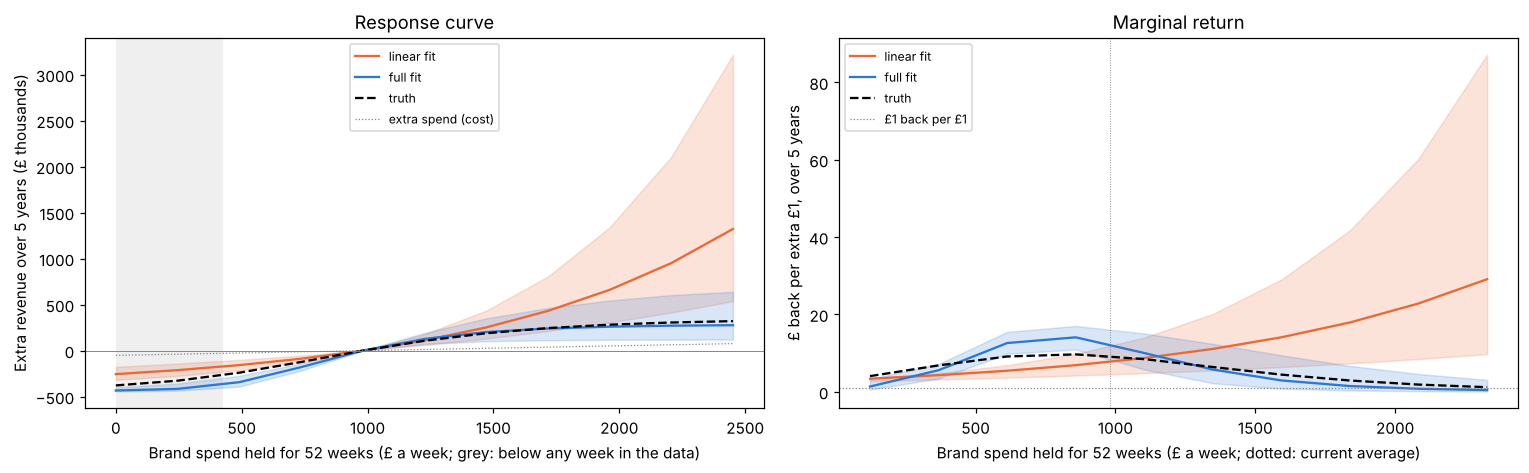

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
weekly_spend = levels * COST_GBP
ax = axes[0]
for label, colour in [("linear", LINEAR_COLOUR), ("full", FULL_COLOUR)]:
    lo, hi = np.percentile(curves[label], TAILS, axis=1)
    ax.fill_between(weekly_spend, lo / 1e3, hi / 1e3, color=colour, alpha=0.18)
    ax.plot(
        weekly_spend, np.median(curves[label], axis=1) / 1e3, color=colour, label=f"{label} fit"
    )
ax.plot(weekly_spend, curves["truth"] / 1e3, color=TRUTH_COLOUR, ls="--", label="truth")
ax.plot(weekly_spend, annual_change / 1e3, color="grey", lw=0.8, ls=":", label="extra spend (cost)")
ax.axvspan(0, exog["brand_spend"].min() * COST_GBP, color="grey", alpha=0.12, lw=0)
ax.axhline(0, color="grey", lw=0.6)
ax.set_xlabel("Brand spend held for 52 weeks (£ a week; grey: below any week in the data)")
ax.set_ylabel("Extra revenue over 5 years (£ thousands)")
ax.set_title("Response curve")
ax.legend(fontsize=8)

# Marginal return: extra revenue per extra £ between neighbouring levels.
ax = axes[1]
mid = (weekly_spend[1:] + weekly_spend[:-1]) / 2
step_cost = np.diff(annual_change)
for label, colour in [("linear", LINEAR_COLOUR), ("full", FULL_COLOUR)]:
    marginal = np.diff(curves[label], axis=0) / step_cost[:, None]
    lo, hi = np.percentile(marginal, TAILS, axis=1)
    ax.fill_between(mid, lo, hi, color=colour, alpha=0.18)
    ax.plot(mid, np.median(marginal, axis=1), color=colour, label=f"{label} fit")
ax.plot(mid, np.diff(curves["truth"]) / step_cost, color=TRUTH_COLOUR, ls="--", label="truth")
ax.axhline(1, color="grey", lw=0.8, ls=":", label="£1 back per £1")
ax.axvline(mean_spend * COST_GBP, color="grey", lw=0.6, ls=":")
ax.set_xlabel("Brand spend held for 52 weeks (£ a week; dotted: current average)")
ax.set_ylabel("£ back per extra £1, over 5 years")
ax.set_title("Marginal return")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [9]:
rows = []
for k in [0.0, 0.5, 1.5, 2.0]:
    i = int(np.argmin(np.abs(MULTIPLES - k)))
    t = curves["truth"][i]
    row = {"brand spend": f"x{k:g} (£{levels[i] * COST_GBP:,.0f} a week)", "truth": f"£{t:,.0f}"}
    for label in ["linear", "full"]:
        draws = curves[label][i]
        lo, hi = np.percentile(draws, TAILS)
        row[label] = f"£{np.median(draws):,.0f} (£{lo:,.0f} to £{hi:,.0f})"
        row[f"{label} error"] = f"{np.median(draws) / t - 1:+.0%}"
    rows.append(row)
print("Extra revenue over 5 years from 52 weeks at each level, against average spend")
pd.DataFrame(rows).set_index("brand spend")

Extra revenue over 5 years from 52 weeks at each level, against average spend


,truth,linear,linear error,full,full error
brand spend,,,,,
x0 (£0 a week),"£-377,879","£-255,067 (£-317,405 to £-175,324)",-33%,"£-433,066 (£-442,668 to £-399,563)",+15%
x0.5 (£490 a week),"£-239,482","£-156,940 (£-212,617 to £-99,871)",-34%,"£-342,708 (£-390,308 to £-273,891)",+43%
"x1.5 (£1,471 a week)","£189,029","£252,321 (£131,989 to £435,055)",+33%,"£202,279 (£102,212 to £351,235)",+7%
"x2 (£1,961 a week)","£282,489","£660,368 (£306,981 to £1,339,798)",+134%,"£260,521 (£117,969 to £545,172)",-8%


In [10]:
mid = (MULTIPLES[1:] + MULTIPLES[:-1]) / 2
step_cost = np.diff(annual_change)
marginal = {"truth": np.diff(curves["truth"]) / step_cost}
for label in ["linear", "full"]:
    marginal[label] = np.median(np.diff(curves[label], axis=0) / step_cost[:, None], axis=1)
table = pd.DataFrame(
    marginal, index=[f"x{m:.3g} (£{m * mean_spend * COST_GBP:,.0f} a week)" for m in mid]
)
print("£ back over 5 years per extra £1 of brand spend, at each spend level (posterior median)")
table.iloc[[3, 4, 6, 8, 9]].round(1)

£ back over 5 years per extra £1 of brand spend, at each spend level (posterior median)


,truth,linear,full
x0.875 (£858 a week),9.7,6.9,14.1
"x1.12 (£1,103 a week)",8.4,8.7,10.0
"x1.62 (£1,593 a week)",4.4,14.1,2.9
"x2.12 (£2,084 a week)",1.9,22.8,0.8
"x2.38 (£2,329 a week)",1.2,29.1,0.4


**Reading the chart and tables.**

- **Near current spend the fits agree.** The next £1 at about £1,100 a week returns £8.40 over five years in the truth, £8.70 in the linear fit and £10.00 in the full fit.
- **Above current spend they part.** The linear fit is a straight line in log sales, so in £ its returns rise with spend: £22.80 per £1 at twice the average. The truth falls to £1.90 and the full fit to £0.80. The full fit says one more £1 stops paying back at about £2,000 a week. The truth is still at £1.20 at £2,330 a week.
- **The full fit overstates cuts on this data set.** Halving spend costs £343,000 in the fit against £239,000 in the truth. Below £420 a week (grey) there is no data.
- **The losses run into a floor.** Sales cannot fall by more than all of them, so the loss from a deep cut levels off near £455,000 (five years of sales). The intervals there are narrow for that reason and not because the fit is sure.

## 5. Is one data set enough?

No. `tools/combined_check.py` fitted both models on 10 simulated data sets with the same truth. It records the sales uplift from holding brand spend at each multiple of its average for 52 weeks, at week 52 and summed over the 52 weeks. The table shows the median error against the truth and the share of 90% intervals that contain it:

In [11]:
runs = pd.read_csv(ROOT / "tools" / "combined_check_results.csv")
runs["error"] = runs["median"] / runs["truth"] - 1
table = runs.groupby(["quantity", "fit"], sort=False).agg(
    error=("error", "median"), coverage=("covered", "mean"), data_sets=("seed", "nunique")
)
table["error"] = table["error"].map("{:+.0%}".format)
table["coverage"] = table["coverage"].map("{:.0%}".format)
table.unstack("fit")

error       coverage       data_sets      
fit                 linear  full   linear  full    linear  full
quantity                                                       
sales week 52: x0     -68%  -12%       0%  100%      10.0  10.0
sales summed: x0      -68%  -12%       0%  100%      10.0  10.0
sales week 52: x0.5   -58%  -12%       0%   80%      10.0  10.0
sales summed: x0.5    -57%  -13%       0%   80%      10.0  10.0
sales week 52: x1.5    +1%   -2%      90%  100%      10.0  10.0
sales summed: x1.5     +1%   -6%      90%  100%      10.0  10.0
sales week 52: x2     +53%   +7%      80%  100%      10.0  10.0
sales summed: x2      +50%   +0%      90%  100%      10.0  10.0
link                   NaN  -20%      NaN   80%       NaN  10.0
decay: brand_spend     NaN   +3%      NaN  100%       NaN  10.0
lambda: brand_spend    NaN   -9%      NaN  100%       NaN  10.0

Across the 10 data sets the full fit is within 13% of the truth at every spend level, with coverage of 80% to 100%. It understates the cuts by about 12%, so this data set (seed 14, not one of the 10) is on the other side. The linear fit understates the loss from switching brand spend off by 68% and overstates the gain from doubling it by about 50%. Its intervals at the two cuts never contain the truth. All 20 fits had 0 divergences.

## 6. What this means

- **One model, one curve.** Adstock, saturation and the same-week link fit together with no sampling problems. The response curve runs through the whole funnel and the long run.
- **The linear fit gets the current return right and the direction of travel wrong.** It says more spend always pays more. The full fit and the truth say returns fall as spend grows.
- **Read the curve near the data.** Across 10 data sets the full fit is within 13% of the truth at every level. One data set can be further out (43% for halving here). Far below the lowest week of spend it is an extrapolation.

**With your own data.**

- Run the checks in order: stationarity and rank (guide 01), the same-week test (guide 04), then the full fit.
- Read a response curve only where the data has been. Below the lowest week of spend the curve is an extrapolation and its interval says so.
- The curve is for one channel with the others held at average. Channels that move together (here the three share a correlation of 0.5) are harder to separate, so plan changes to one at a time where you can.